In [2]:
import pandas as pd
data=pd.read_csv("insurance.csv")

In [ ]:
data.head()

NameError: name 'data' is not defined

In [4]:
data.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [5]:
data.shape

(1338, 7)

In [6]:
print("number of rows",data.shape[0])
print("number of columns",data.shape[1])

number of rows 1338
number of columns 7


In [7]:
# checking for missing values
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [8]:
data.describe(include='all')

,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


<Figure size 600x600 with 0 Axes>

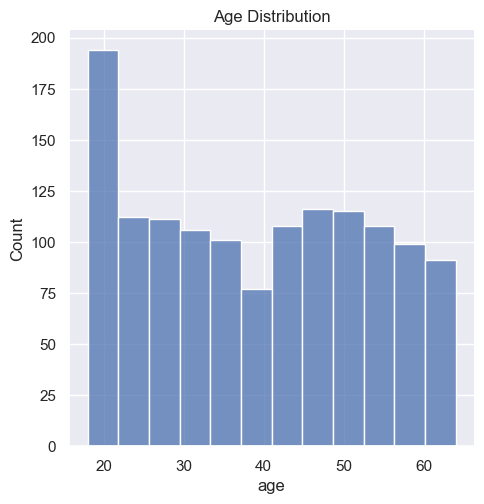

In [9]:
# distribution of age value
import seaborn as sns
import matplotlib.pyplot as plt
sns.set()
plt.figure(figsize=(6,6))
sns.displot(data['age'])
plt.title('Age Distribution')
plt.show()

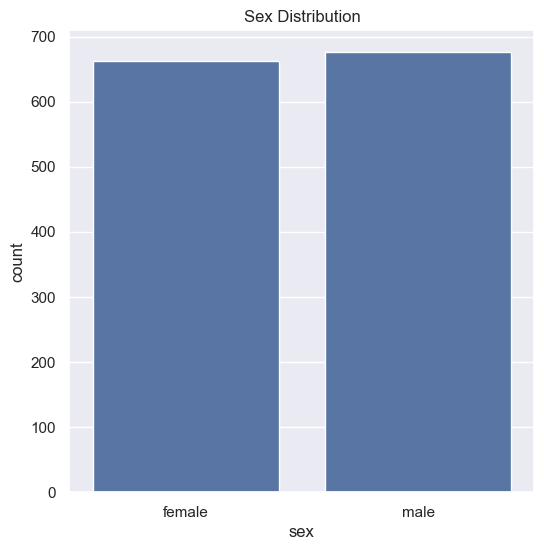

In [10]:
# Gender column
plt.figure(figsize=(6,6))
sns.countplot(x='sex', data=data)
plt.title('Sex Distribution')
plt.show()

In [11]:
data['sex'].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

<Figure size 600x600 with 0 Axes>

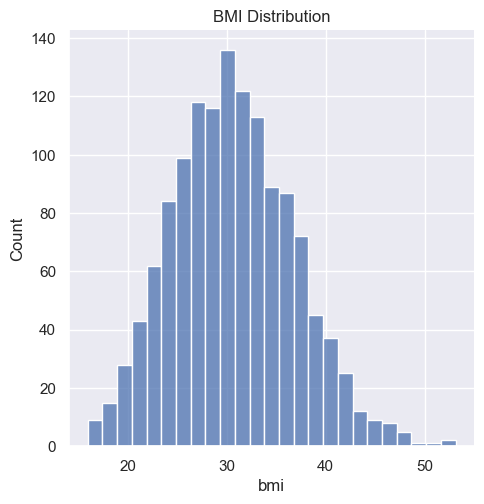

In [12]:
# bim distribution 
plt.figure(figsize=(6,6))
sns.displot(data['bmi'])
plt.title('BMI Distribution')
plt.show()

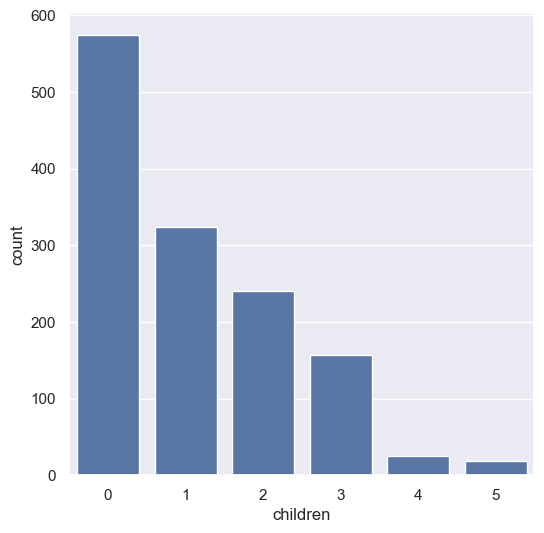

In [13]:
# children column
plt.figure(figsize = (6,6))
sns.countplot(x='children', data=data)
plt.show()

In [14]:
data['children'].value_counts()

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

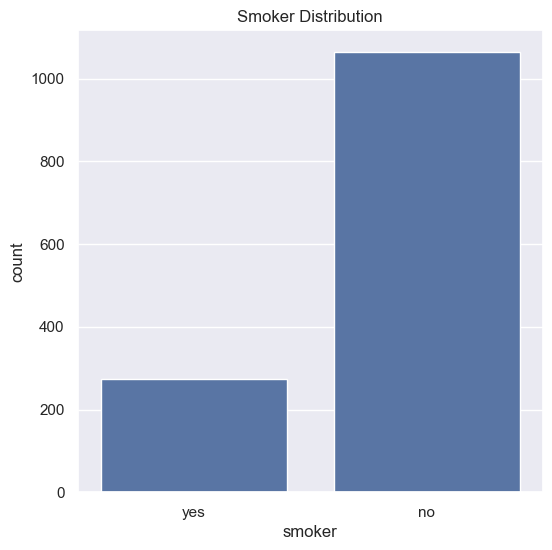

In [15]:
# smoker column
plt.figure(figsize=(6,6))
sns.countplot(x='smoker', data=data)
plt.title('Smoker Distribution')
plt.show()

In [16]:
data['smoker'].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

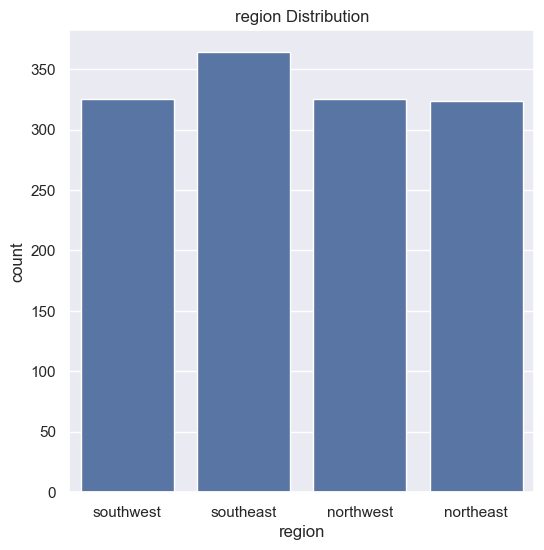

In [17]:
# region column
plt.figure(figsize=(6,6))
sns.countplot(x='region', data=data)
plt.title('region Distribution')
plt.show()

In [18]:
data['region'].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

<Figure size 600x600 with 0 Axes>

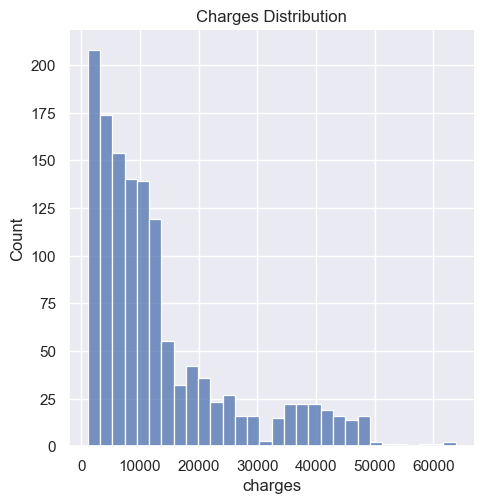

In [19]:
# distribution of charges value
plt.figure(figsize=(6,6))
sns.displot(data['charges'])
plt.title('Charges Distribution')
plt.show()

Get Overall Statistics About The Dataset

In [20]:
data.describe(include='all')

,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


mapping the unique keys

In [21]:
data['sex'].unique()
data['sex']=data['sex'].map({'female':0,'male':1})

In [22]:
data['smoker'].unique()
data['smoker']=data['smoker'].map({'yes':0,'no':1})

In [23]:
data['region'].unique()
data['region']=data['region'].map({'southwest':1,'southeast':2,'northwest':3,'northeast':4})

In [24]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,0,1,16884.92400
1,18,1,33.770,1,1,2,1725.55230
2,28,1,33.000,3,1,2,4449.46200
3,33,1,22.705,0,1,3,21984.47061
4,32,1,28.880,0,1,3,3866.85520


Store Feature Matrix In X and Response(Target) In Vector y

In [25]:
data.columns
X=data.drop(['charges'],axis=1)
y=data['charges']

Train/Test split

Split data into two part : a training set and a testing set
Train the model(s) on training set
Test the Model(s) on Testing set#

In [26]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=100)

Model Training

In [27]:
from sklearn.linear_model import LinearRegression
#Initialize the model
lr = LinearRegression()
# Fit the model to the training data
lr.fit(X_train,y_train)

LinearRegression()

Prediction on Test Data

In [28]:
y_pred=lr.predict(X_test)
df=pd.DataFrame({'Actual':y_test,'Lr':y_pred})
df

,Actual,Lr
12,1826.84300,4243.315613
306,20177.67113,4369.130655
318,7421.19455,8459.055910
815,1877.92940,2915.207396
157,15518.18025,24708.665557
...,...,...
713,1984.45330,6480.133546
1282,14283.45940,23610.114962
531,14043.47670,14857.574372
537,8825.08600,9955.079471


Compare Performance

<function matplotlib.pyplot.legend(*args, **kwargs) -> 'Legend'>

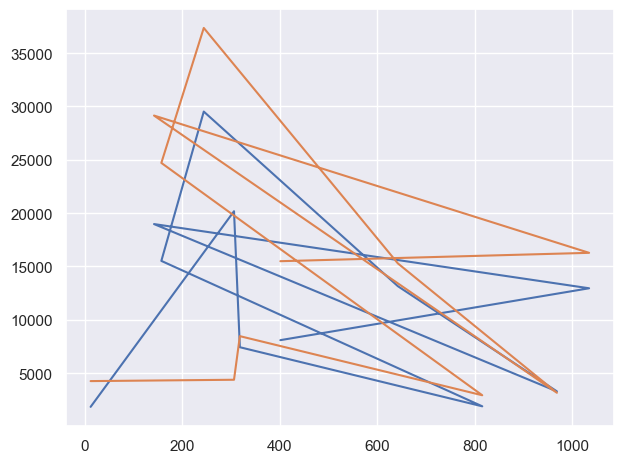

In [29]:
import matplotlib.pyplot as plt
plt.plot(df['Actual'].iloc[0:11],label='Actual')
plt.plot(df['Lr'].iloc[0:11],label='Lr')
plt.tight_layout()
plt.legend

In [30]:
from sklearn import metrics
score=metrics.r2_score(y_test,y_pred)
print(score)

0.7942462599118463


In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn. ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor 

from sklearn.tree import DecisionTreeRegressor

In [32]:
svm = SVR()
svm.fit(X_train,y_train)

SVR()

In [33]:
y_pred=svm.predict(X_test)
df=pd.DataFrame({'Actual':y_test,'svm':y_pred})
df

,Actual,svm
12,1826.84300,9065.696286
306,20177.67113,9085.766528
318,7421.19455,9194.232909
815,1877.92940,9053.321270
157,15518.18025,9048.382988
...,...,...
713,1984.45330,9063.247148
1282,14283.45940,9050.736570
531,14043.47670,9305.152023
537,8825.08600,9210.225079


<function matplotlib.pyplot.legend(*args, **kwargs) -> 'Legend'>

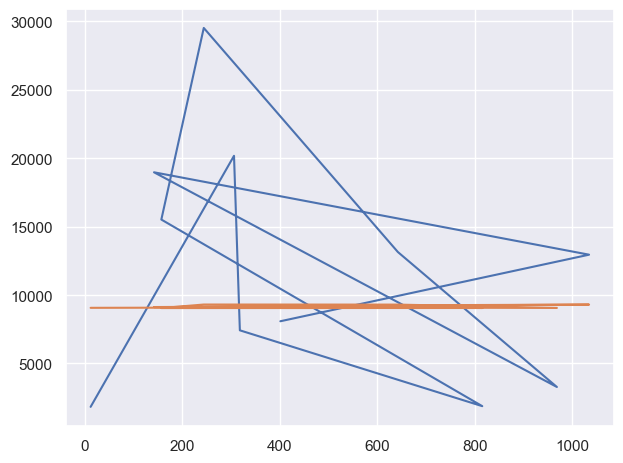

In [34]:
import matplotlib.pyplot as plt
plt.plot(df['Actual'].iloc[0:11],label='Actual')
plt.plot(df['svm'].iloc[0:11],label='svm')
plt.tight_layout()
plt.legend

In [35]:
rf = RandomForestRegressor()
rf.fit(X_train,y_train)

RandomForestRegressor()

In [36]:
y_pred=rf.predict(X_test)
df=pd.DataFrame({'Actual':y_test,'rf':y_pred})
df

,Actual,rf
12,1826.84300,3641.318987
306,20177.67113,4611.812283
318,7421.19455,13469.933895
815,1877.92940,2544.621054
157,15518.18025,17706.685964
...,...,...
713,1984.45330,6887.460146
1282,14283.45940,14379.509912
531,14043.47670,13930.905820
537,8825.08600,8848.548316


<function matplotlib.pyplot.legend(*args, **kwargs) -> 'Legend'>

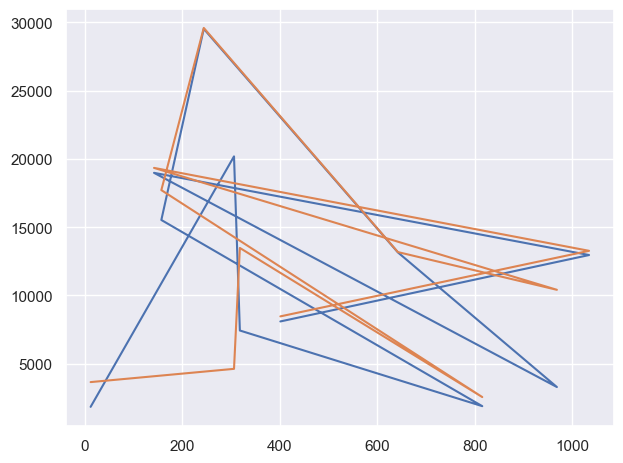

In [37]:
import matplotlib.pyplot as plt
plt.plot(df['Actual'].iloc[0:11],label='Actual')
plt.plot(df['rf'].iloc[0:11],label='rf')
plt.tight_layout()
plt.legend

In [38]:
gr = GradientBoostingRegressor()
gr.fit(X_train,y_train)

GradientBoostingRegressor()

In [39]:
y_pred=gr.predict(X_test)
df=pd.DataFrame({'Actual':y_test,'gr':y_pred})
df

,Actual,gr
12,1826.84300,3991.263055
306,20177.67113,6265.797064
318,7421.19455,10389.576532
815,1877.92940,2692.448330
157,15518.18025,16075.139058
...,...,...
713,1984.45330,4603.257114
1282,14283.45940,14830.065026
531,14043.47670,14470.821712
537,8825.08600,9571.086218


<function matplotlib.pyplot.legend(*args, **kwargs) -> 'Legend'>

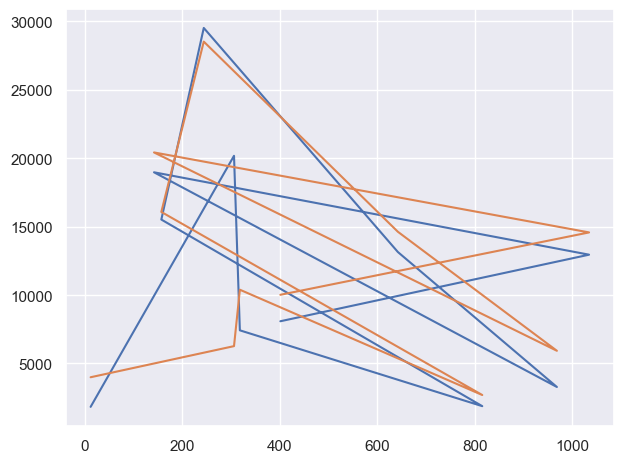

In [40]:
import matplotlib.pyplot as plt
plt.plot(df['Actual'].iloc[0:11],label='Actual')
plt.plot(df['gr'].iloc[0:11],label='gr')
plt.tight_layout()
plt.legend

In [41]:
knn_regressor = KNeighborsRegressor()
knn_regressor.fit(X_train,y_train)

KNeighborsRegressor()

In [42]:
y_pred=knn_regressor.predict(X_test)
df=pd.DataFrame({'Actual':y_test,'knn_regressor':y_pred})
df

,Actual,knn_regressor
12,1826.84300,10366.739946
306,20177.67113,6957.587070
318,7421.19455,14479.604840
815,1877.92940,5115.169462
157,15518.18025,4626.009130
...,...,...
713,1984.45330,4562.051360
1282,14283.45940,4179.903410
531,14043.47670,19936.476400
537,8825.08600,12123.081060


<function matplotlib.pyplot.legend(*args, **kwargs) -> 'Legend'>

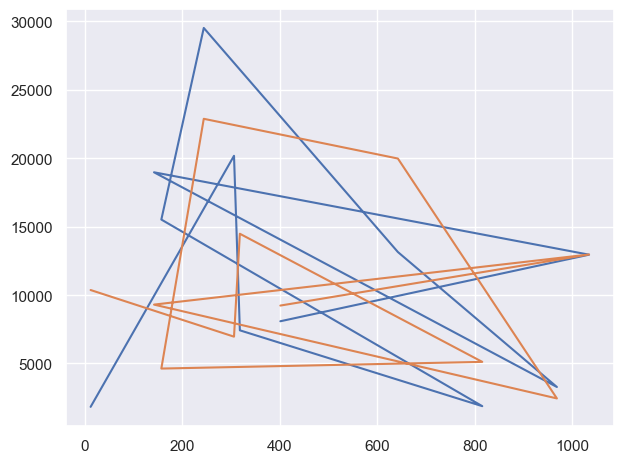

In [43]:
import matplotlib.pyplot as plt
plt.plot(df['Actual'].iloc[0:11],label='Actual')
plt.plot(df['knn_regressor'].iloc[0:11],label='knn_regressor')
plt.tight_layout()
plt.legend

In [44]:
print(df)

           Actual  knn_regressor
12     1826.84300   10366.739946
306   20177.67113    6957.587070
318    7421.19455   14479.604840
815    1877.92940    5115.169462
157   15518.18025    4626.009130
...           ...            ...
713    1984.45330    4562.051360
1282  14283.45940    4179.903410
531   14043.47670   19936.476400
537    8825.08600   12123.081060
1015  12124.99240   15607.031674

[268 rows x 2 columns]


In [45]:

dt_regressor = DecisionTreeRegressor()
dt_regressor.fit(X_train, y_train)


DecisionTreeRegressor()

In [46]:
y_pred=dt_regressor.predict(X_test)
df=pd.DataFrame({'Actual':y_test,'dt_regressor':y_pred})
df

,Actual,dt_regressor
12,1826.84300,2473.33410
306,20177.67113,4260.74400
318,7421.19455,28340.18885
815,1877.92940,1748.77400
157,15518.18025,16450.89470
...,...,...
713,1984.45330,1646.42970
1282,14283.45940,13747.87235
531,14043.47670,13844.79720
537,8825.08600,8968.33000


<function matplotlib.pyplot.legend(*args, **kwargs) -> 'Legend'>

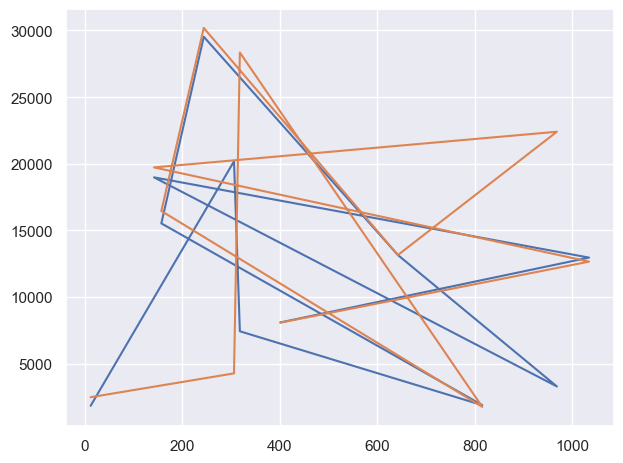

In [47]:
import matplotlib.pyplot as plt
plt.plot(df['Actual'].iloc[0:11],label='Actual')
plt.plot(df['dt_regressor'].iloc[0:11],label='dt_regressor')
plt.tight_layout()
plt.legend

In [48]:
print(df)

           Actual  dt_regressor
12     1826.84300    2473.33410
306   20177.67113    4260.74400
318    7421.19455   28340.18885
815    1877.92940    1748.77400
157   15518.18025   16450.89470
...           ...           ...
713    1984.45330    1646.42970
1282  14283.45940   13747.87235
531   14043.47670   13844.79720
537    8825.08600    8968.33000
1015  12124.99240   24513.09126

[268 rows x 2 columns]


In [49]:
data={'age':40,
     'sex':1,
     'bmi':40.30,
     'children':4,
     'smoker':1,
     'region':2}
df=pd.DataFrame(data,index=[0])
df

,age,sex,bmi,children,smoker,region
0,40,1,40.3,4,1,2


In [50]:
new_pred=lr.predict(df)
print("Medical Insurance Cost For New Customer Is:",new_pred[0])

Medical Insurance Cost For New Customer Is: 12836.582493753765


In [51]:
lr= LinearRegression()
lr.fit(X,y)

LinearRegression()

In [52]:
new_pred=svm.predict(df)
print("Medical Insurance Cost For New Customer Is:",new_pred[0])

Medical Insurance Cost For New Customer Is: 9171.129850420943


In [53]:
svm= SVR()
svm.fit(X,y)

SVR()

In [54]:
new_pred=rf.predict(df)
print("Medical Insurance Cost For New Customer Is:",new_pred[0])

Medical Insurance Cost For New Customer Is: 11486.22060150001


In [55]:
rf = RandomForestRegressor()
rf.fit(X,y)

RandomForestRegressor()

In [56]:
new_pred=gr.predict(df)
print("Medical Insurance Cost For New Customer Is:",new_pred[0])

Medical Insurance Cost For New Customer Is: 8278.25460254419


In [57]:
gr = GradientBoostingRegressor()
gr.fit(X,y)

GradientBoostingRegressor()

In [58]:
new_pred=knn_regressor.predict(df)
print("Medical Insurance Cost For New Customer Is:",new_pred[0])

Medical Insurance Cost For New Customer Is: 25461.204488000003


In [59]:
knn_regressor = KNeighborsRegressor()
knn_regressor.fit(X,y)

KNeighborsRegressor()

In [60]:
new_pred=dt_regressor.predict(df)
print("Medical Insurance Cost For New Customer Is:",new_pred[0])

Medical Insurance Cost For New Customer Is: 8162.71625


In [61]:
dt_regressor = DecisionTreeRegressor()
dt_regressor.fit(X, y)


DecisionTreeRegressor()

In [62]:
lr.score(X_test,y_test)

0.7972358113557931

In [63]:
svm.score(X_test,y_test)

-0.14375163276911174

In [64]:
rf.score(X_test,y_test)

0.9811114065779121

In [65]:
gr.score(X_test,y_test)

0.9303730950127574

In [66]:
knn_regressor.score(X_test,y_test)

0.4268331345509828

In [67]:
dt_regressor.score(X_test,y_test)

1.0

In [68]:
import joblib


In [69]:
joblib.dump(lr,'our_model')

['our_model']

In [70]:
model= joblib.load('our_model')

In [71]:
model.predict(df)

array([12957.7339639])

In [72]:
from tkinter import *

In [ ]:
import joblib

In [ ]:
import warnings
warnings.filterwarnings("ignore", message="X does not have valid feature names")


In [ ]:
def show_entry():
    p1=float(e1.get())
    p2=float(e2.get())
    p3=float(e3.get())
    p4=float(e4.get())
    p5=float(e5.get())
    p6=float(e6.get())

    model= joblib.load("our_model")
    result=  model.predict([[p1,p2,p3,p4,p5,p6]])


    Label(master,text= "Insurance Cost").grid(row=7)
    Label(master, text= result).grid(row=8)



master = Tk()
master.title("Insurance Cost Prediction")
label= Label(master,text= "Insurance Cost Prediction", bg= "black",fg= "white").grid(row=0,columnspan=2)
Label(master,text= "Enter your age").grid(row=1)
Label(master,text= "Male or Female 1/0").grid(row=2)
Label(master,text= "Enter your bmi").grid(row=3)
Label(master,text= "Enter number of children").grid(row=4)
Label(master,text= "Smoker 0/1").grid(row=5)
Label(master,text= "region 1/2/3/4").grid(row=6)

e1= Entry(master)
e2= Entry(master)
e3= Entry(master)
e4= Entry(master)
e5= Entry(master)
e6= Entry(master)




e1.grid(row=1,column =1)
e2.grid(row=2,column =1)
e3.grid(row=3,column =1)
e4.grid(row=4,column =1)
e5.grid(row=5,column =1)
e6.grid(row=6,column =1)

Button(master,text="Predict",command=show_entry).grid()


mainloop()

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import joblib

# Load dataset (update the filename if needed)
df = pd.read_csv("insurance.csv")  # Ensure the dataset is in your directory

# Convert categorical variables if needed
df = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=True)

# Define features (X) and target variable (y)
X = df.drop("charges", axis=1)
y = df["charges"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Save the trained model
joblib.dump(model, "insurance_model.pkl")
print("Model saved successfully as insurance_model.pkl!")




Model saved successfully as insurance_model.pkl!


In [3]:
import os
print(os.listdir())  # Lists all files in the current directory


['health2 (1).ipynb']


In [4]:
import pandas as pd

# Sample insurance data
data = {
    "age": [25, 45, 32, 50],
    "bmi": [22.0, 27.5, 24.1, 30.2],
    "children": [0, 2, 1, 3],
    "sex": ["male", "female", "male", "female"],
    "smoker": ["no", "yes", "no", "yes"],
    "region": ["southeast", "northwest", "southwest", "northeast"],
    "charges": [3200, 15000, 4500, 17000]
}

# Convert to DataFrame
df = pd.DataFrame(data)

# Save as CSV
df.to_csv("insurance.csv", index=False)
print("✅ insurance.csv created successfully!")


✅ insurance.csv created successfully!


In [5]:
import os
print("insurance.csv exists:", os.path.exists("insurance.csv"))


insurance.csv exists: True


In [6]:
df = pd.read_csv("insurance.csv")
print(df.head())  # Check if data is loaded correctly


   age   bmi  children     sex smoker     region  charges
0   25  22.0         0    male     no  southeast     3200
1   45  27.5         2  female    yes  northwest    15000
2   32  24.1         1    male     no  southwest     4500
3   50  30.2         3  female    yes  northeast    17000


In [11]:
import joblib

# Load the model
model = joblib.load("insurance_model.pkl")

# Check the feature names (if saved in a pipeline)
print("Model Features:", model.feature_names_in_)


Model Features: ['age' 'bmi' 'children' 'sex_male' 'smoker_yes' 'region_northwest'
 'region_southeast' 'region_southwest']


In [12]:
import pandas as pd

df = pd.read_csv("insurance.csv")  # Load your dataset
df = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=False)  # No column dropped
print(df.columns)  # Check all columns
print("Total features:", len(df.columns) - 1)  # Exclude 'charges'


Index(['age', 'bmi', 'children', 'charges', 'sex_female', 'sex_male',
       'smoker_no', 'smoker_yes', 'region_northeast', 'region_northwest',
       'region_southeast', 'region_southwest'],
      dtype='object')
Total features: 11


import pandas as pd

df = pd.read_csv("insurance.csv")  # Load your dataset
df = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=False)  # No column dropped
print(df.columns)  # Check all columns
print("Total features:", len(df.columns) - 1)  # Exclude 'charges'
